In [160]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

In [161]:
path='user_personalized_features.csv'
df=pd.read_csv(path)
df.head()

,Unnamed: 0,User_ID,Age,Gender,Location,Income,Interests,Last_Login_Days_Ago,Purchase_Frequency,Average_Order_Value,Total_Spending,Product_Category_Preference,Time_Spent_on_Site_Minutes,Pages_Viewed,Newsletter_Subscription
0,0,#1,56,Male,Suburban,38037,Sports,5,7,18,2546,Books,584,38,True
1,1,#2,46,Female,Rural,103986,Technology,15,7,118,320,Electronics,432,40,False
2,2,#3,32,Female,Suburban,101942,Sports,28,1,146,3766,Apparel,306,1,True
3,3,#4,60,Female,Suburban,71612,Fashion,18,3,163,4377,Apparel,527,29,False
4,4,#5,25,Male,Suburban,49725,Travel,2,5,141,4502,Health & Beauty,53,10,True


In [162]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Unnamed: 0                   1000 non-null   int64
 1   User_ID                      1000 non-null   str  
 2   Age                          1000 non-null   int64
 3   Gender                       1000 non-null   str  
 4   Location                     1000 non-null   str  
 5   Income                       1000 non-null   int64
 6   Interests                    1000 non-null   str  
 7   Last_Login_Days_Ago          1000 non-null   int64
 8   Purchase_Frequency           1000 non-null   int64
 9   Average_Order_Value          1000 non-null   int64
 10  Total_Spending               1000 non-null   int64
 11  Product_Category_Preference  1000 non-null   str  
 12  Time_Spent_on_Site_Minutes   1000 non-null   int64
 13  Pages_Viewed                 1000 non-null   int64
 14  News

In [163]:
#重复值查询
#1.用户是否重复
df.User_ID.unique()

<ArrowStringArray>
[   '#1',    '#2',    '#3',    '#4',    '#5',    '#6',    '#7',    '#8',
    '#9',   '#10',
 ...
  '#991',  '#992',  '#993',  '#994',  '#995',  '#996',  '#997',  '#998',
  '#999', '#1000']
Length: 1000, dtype: str

In [164]:
#2.商品偏好唯一性
df.groupby('User_ID').Product_Category_Preference.unique()

User_ID
#1                 [Books]
#10          [Electronics]
#100             [Apparel]
#1000    [Health & Beauty]
#101     [Health & Beauty]
               ...        
#995             [Apparel]
#996             [Apparel]
#997             [Apparel]
#998               [Books]
#999         [Electronics]
Name: Product_Category_Preference, Length: 1000, dtype: object

In [165]:
#商品偏好分布
df.Product_Category_Preference.value_counts()

Product_Category_Preference
Apparel            218
Electronics        209
Books              198
Home & Kitchen     189
Health & Beauty    186
Name: count, dtype: int64

In [166]:
#爱好分布
df.Interests.value_counts()

Interests
Sports        213
Fashion       209
Travel        196
Food          196
Technology    186
Name: count, dtype: int64

In [167]:
#缺失值查询
df.isnull().sum().sum()

np.int64(0)

In [168]:
#异常值查询
df[(df['Age'] < 10) | (df['Age'] > 100)].shape[0]

0

In [169]:
#收入高低分析
income_33 = df['Income'].quantile(0.33)
income_66 = df['Income'].quantile(0.66)
def income_level(income):
    if income <= income_33:
        return 'Low'
    elif income <= income_66:
        return 'Medium'
    else:
        return 'High'
df['Income_Level'] = df['Income'].apply(income_level)

In [170]:
#可视化

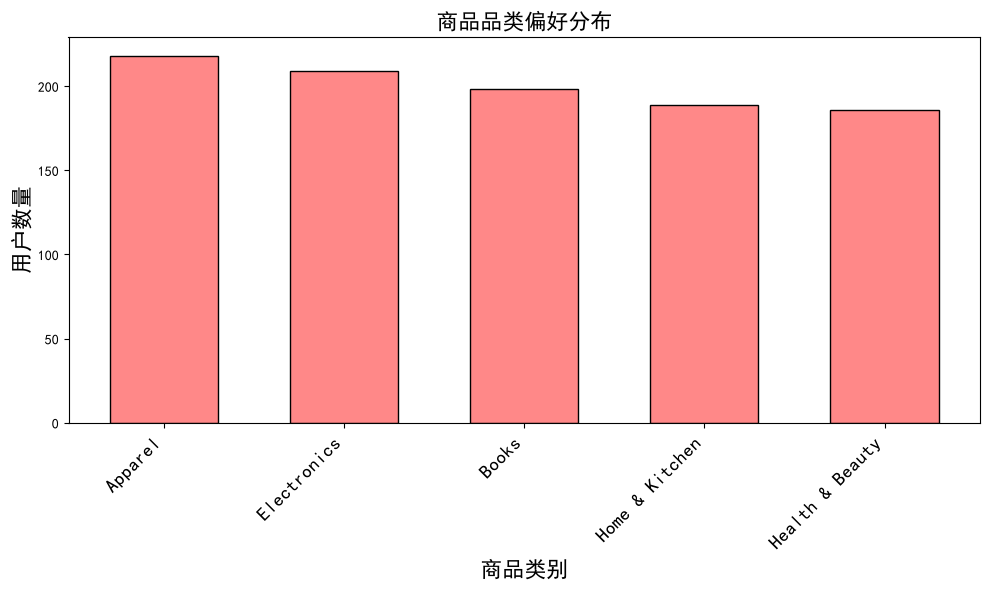

In [171]:
ct=df.Product_Category_Preference.value_counts()
plt.figure(figsize=(10, 6))
plt.bar(ct.index,ct.values,color='#ff8888',edgecolor='black',width=0.6)
plt.title('商品品类偏好分布', fontsize=16)
plt.xlabel('商品类别', fontsize=16)
plt.ylabel('用户数量', fontsize=16)
plt.xticks(rotation=45, ha='right',fontsize=14)
plt.tight_layout()
plt.show()

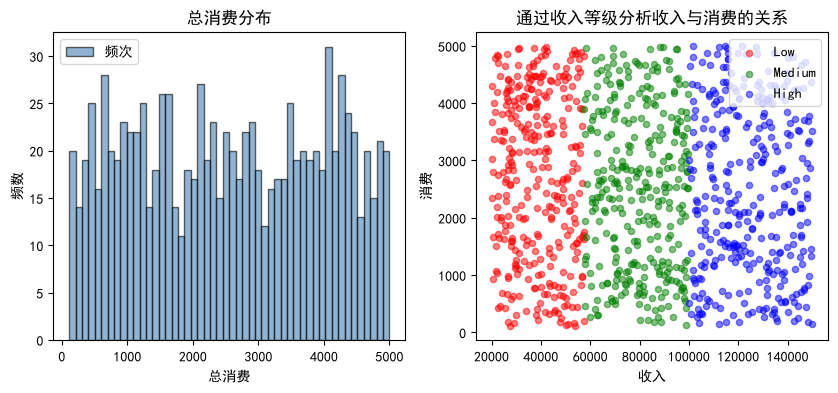

In [172]:
#消费分布分析
#1.Total_Spending发布
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.hist(df['Total_Spending'],bins=50,edgecolor='black',color='steelblue',alpha=0.6,label='频次')
plt.title('总消费分布')
plt.xlabel('总消费')
plt.ylabel('频数')
plt.legend()

#2.Income&otal_Spending分布
plt.subplot(1,2,2)
colors = {'Low': 'r', 'Medium': 'g', 'High': 'b'}
for level in ['Low', 'Medium', 'High']:
    subset = df[df['Income_Level'] == level]
    plt.scatter(subset['Income'], subset['Total_Spending'], 
                          alpha=0.5, label=level, c=colors[level], s=20)
plt.title('通过收入等级分析收入与消费的关系', fontsize=12)
plt.xlabel('收入')
plt.ylabel('消费')
plt.legend()

In [173]:
df['Last_Login_Days_Ago'].min()

np.int64(1)

In [174]:
df['Last_Login_Days_Ago'].max()

np.int64(29)

In [175]:
#用户留存分析
#由于数据集不存在大于30以上数据，根本不存在低留存用户和流失用户.
#1.划分留存区间
def lc_level(days):
    if days<=7:
        return '高留存用户'
    elif days<=30:
        return '中留存用户'
    elif days<=90:
        return '低留存用户'
    else:
        return '流失用户'

df['留存区间']=df['Last_Login_Days_Ago'].apply(lc_level)

In [176]:
#2.统计各区间用户数量
lc_count=df['留存区间'].value_counts().sort_index()
lc_count

留存区间
中留存用户    795
高留存用户    205
Name: count, dtype: int64

In [177]:
#3.各留存区间核心指标统计
zb=df.groupby('留存区间').agg(
    用户数量=('User_ID','count'),
    平均购买频次=('Purchase_Frequency','mean'),
    平均总消费=('Total_Spending','mean'),
    平均页面浏览量=('Pages_Viewed','mean')).round(2)
print('各留存区间核心指标')
zb

各留存区间核心指标


,用户数量,平均购买频次,平均总消费,平均页面浏览量
留存区间,,,,
中留存用户,795,4.61,2586.77,24.16
高留存用户,205,4.70,2421.83,25.36


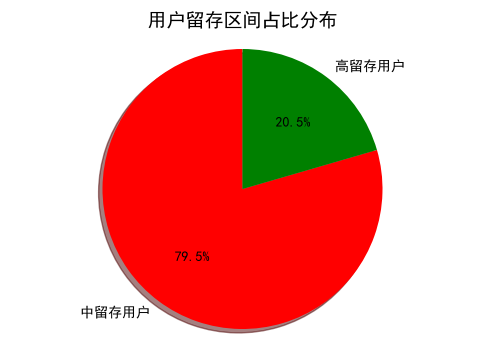

In [178]:
#留存分析可视化
#1.留存区间用户占比饼图
plt.figure(figsize=(6,4))
plt.pie(lc_count.values,labels=lc_count.index,autopct='%.1f%%',colors=['r','g','b','black'],startangle=90,shadow=True)
plt.title('用户留存区间占比分布',fontsize=14)
plt.tight_layout
plt.axis('equal')
plt.show()

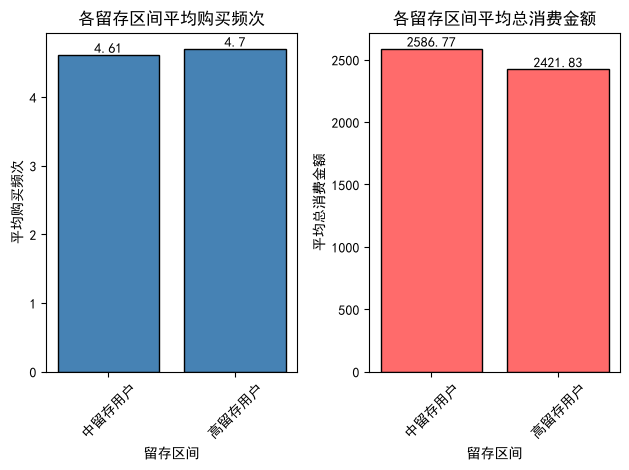

In [179]:
#2.各留存区间核心指标对比
plt.subplot(1,2,1)
plt.bar(zb.index,zb['平均购买频次'],color='steelblue',edgecolor='black')
plt.title('各留存区间平均购买频次')
plt.xlabel('留存区间')
plt.ylabel('平均购买频次')
for x,y in zip(zb.index,zb['平均购买频次']):
    plt.text(x,y,y,ha='center',va='bottom')
plt.xticks(rotation=45)

plt.subplot(1,2,2)
plt.bar(zb.index,zb['平均总消费'],color='#ff6b6b',edgecolor='black')
plt.title('各留存区间平均总消费金额')
plt.xlabel('留存区间')
plt.ylabel('平均总消费金额')
plt.xticks(rotation=45)
for x,y in zip(zb.index,zb['平均总消费']):
    plt.text(x,y,y,ha='center',va='bottom')
plt.tight_layout()
plt.show()

In [180]:
#由于数据集数据不够，因此上述可视化缺少了对低留存用户和流失用户的分析，但是分析方法是一致的

In [181]:
#RFM分层分析
'''
R(recency):最近一次登录距今天数，数值越小，分数越高
F(frequency):购买频次，数值越大，分数越高
M(monetary):总消费金额，数值越大，分数越高
'''

'\nR(recency):最近一次登录距今天数，数值越小，分数越高\nF(frequency):购买频次，数值越大，分数越高\nM(monetary):总消费金额，数值越大，分数越高\n'

In [182]:
#1.提取rfm核心字段
rfm_df=df[['User_ID','Last_Login_Days_Ago','Purchase_Frequency','Total_Spending']].copy()
rfm_df.columns=['User_ID','R','F','M']

In [183]:
#2.分位数打分(1-5分,等频率分箱)
rfm_df['R_score']=pd.qcut(rfm_df['R'],q=5,labels=[5,4,3,2,1])#R越小越好
rfm_df['F_score']=pd.qcut(rfm_df['F'],q=5,labels=[1,2,3,4,5])#F,M越大越好
rfm_df['M_score']=pd.qcut(rfm_df['M'],q=5,labels=[1,2,3,4,5])

In [184]:
#3.分数转为整数
for col in ['R_score','F_score','M_score']:
    rfm_df[col]=rfm_df[col].astype(int)

In [185]:
#4.计算RFM总分+分层编码
rfm_df['RFM总分']=rfm_df['R_score']+rfm_df['F_score']+rfm_df['M_score']
rfm_df['RFM编码']=rfm_df['R_score'].astype(str)+rfm_df['F_score'].astype(str)+rfm_df['M_score'].astype(str)

In [186]:
#5.匹配回原数据集
df=df.merge(rfm_df,on='User_ID',how='left')
df.head()

,Unnamed: 0,User_ID,Age,Gender,Location,Income,Interests,Last_Login_Days_Ago,Purchase_Frequency,Average_Order_Value,...,Income_Level,留存区间,R,F,M,R_score,F_score,M_score,RFM总分,RFM编码
0,0,#1,56,Male,Suburban,38037,Sports,5,7,18,...,Low,高留存用户,5,7,2546,5,4,3,12,543
1,1,#2,46,Female,Rural,103986,Technology,15,7,118,...,High,中留存用户,15,7,320,3,4,1,8,341
2,2,#3,32,Female,Suburban,101942,Sports,28,1,146,...,High,中留存用户,28,1,3766,1,1,4,6,114
3,3,#4,60,Female,Suburban,71612,Fashion,18,3,163,...,Medium,中留存用户,18,3,4377,3,2,5,10,325
4,4,#5,25,Male,Suburban,49725,Travel,2,5,141,...,Low,高留存用户,2,5,4502,5,3,5,13,535


In [187]:
#用户分层
def rfm_user_level(row):
    r,f,m=row['R_score'],row['F_score'],row['M_score']
    if r>=4 and f>=4 and m>=4:
        return '高价值用户'
    elif r>=4 and f>=4 and m<4:
        return '潜力用户'
    elif r>=4 and f<4 and m<4:
        return '新用户'
    elif r>=4 and f<4 and m>=4:    
        return '高价值新用户'
    elif r<4 and f>=4 and m>=4:
        return '高价值流失用户'
    elif r<4 and f>=4 and m<4:
        return '一般价值流失用户'
    elif r<4 and f<4 and m>=4:
        return '高价值沉睡用户'
    else:
        return '低价值流失用户'    

In [188]:
rfm_df['用户分层']=rfm_df.apply(rfm_user_level,axis=1)
df=df.merge(rfm_df[['User_ID','用户分层']],on='User_ID',how='left')
df.head()

,Unnamed: 0,User_ID,Age,Gender,Location,Income,Interests,Last_Login_Days_Ago,Purchase_Frequency,Average_Order_Value,...,留存区间,R,F,M,R_score,F_score,M_score,RFM总分,RFM编码,用户分层
0,0,#1,56,Male,Suburban,38037,Sports,5,7,18,...,高留存用户,5,7,2546,5,4,3,12,543,潜力用户
1,1,#2,46,Female,Rural,103986,Technology,15,7,118,...,中留存用户,15,7,320,3,4,1,8,341,一般价值流失用户
2,2,#3,32,Female,Suburban,101942,Sports,28,1,146,...,中留存用户,28,1,3766,1,1,4,6,114,高价值沉睡用户
3,3,#4,60,Female,Suburban,71612,Fashion,18,3,163,...,中留存用户,18,3,4377,3,2,5,10,325,高价值沉睡用户
4,4,#5,25,Male,Suburban,49725,Travel,2,5,141,...,高留存用户,2,5,4502,5,3,5,13,535,高价值新用户


In [189]:
user_level_count=rfm_df['用户分层'].value_counts().sort_values(ascending=False)
user_level_count

用户分层
低价值流失用户     241
新用户         185
高价值沉睡用户     163
高价值新用户      110
一般价值流失用户    101
高价值流失用户      74
潜力用户         73
高价值用户        53
Name: count, dtype: int64

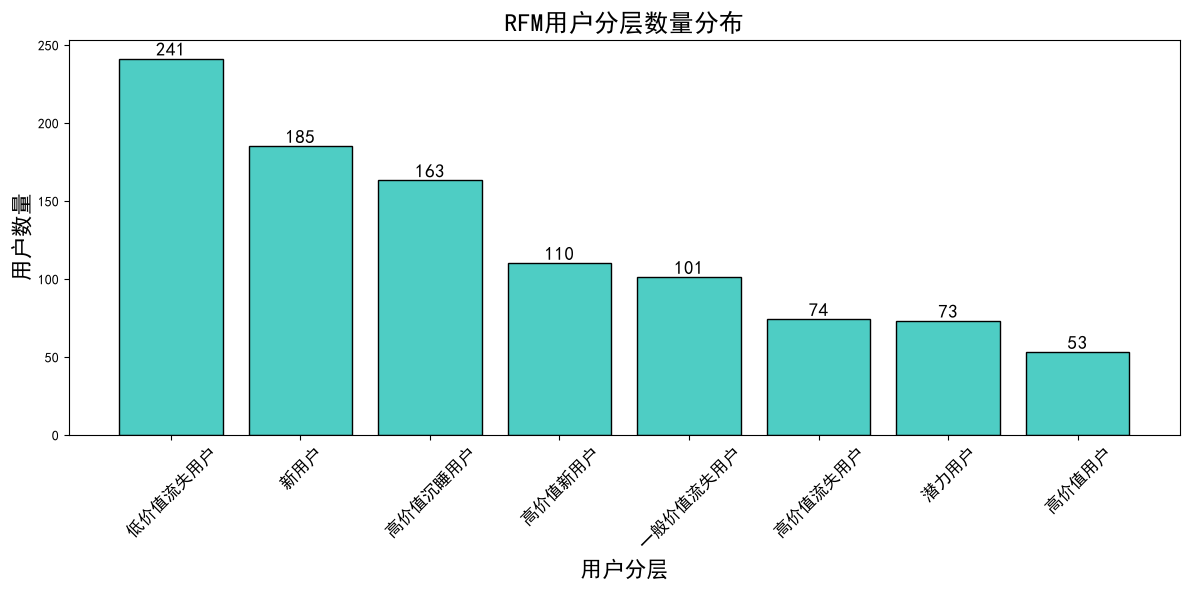

In [197]:
#用户分层可视化
#1.各分层用户数量柱状图
plt.figure(figsize=(12,6))
plt.bar(user_level_count.index,user_level_count.values,color='#4ecdc4',edgecolor='black')
plt.title('RFM用户分层数量分布',fontsize=18)
plt.xlabel('用户分层',fontsize=16)
plt.ylabel('用户数量',fontsize=16)
for x,y in zip(user_level_count.index,user_level_count.values):
    plt.text(x,y,y,ha='center',va='bottom',fontsize=14)
plt.xticks(rotation=45,fontsize=12)
plt.tight_layout()
plt.show()

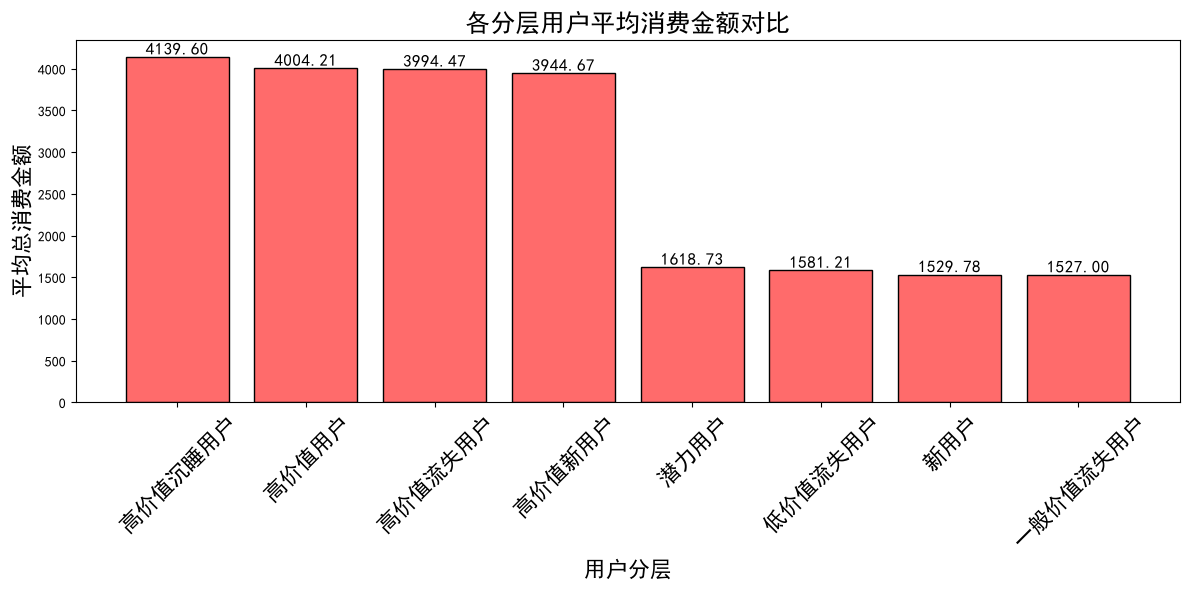

In [205]:
#2.各分层用户平均消费金额对比
level_avg_spend=df.groupby('用户分层')['Total_Spending'].mean().sort_values(ascending=False)
plt.figure(figsize=(12,6))
plt.bar(level_avg_spend.index,level_avg_spend.values,color='#ff6b6b',edgecolor='black')
plt.title('各分层用户平均消费金额对比',fontsize=18)
plt.xlabel('用户分层',fontsize=16)
plt.ylabel('平均总消费金额',fontsize=16)
for x,y in zip(level_avg_spend.index,level_avg_spend.values):
    plt.text(x,y,f'{y:.2f}',ha='center',va='bottom',fontsize=12)
plt.xticks(rotation=45,fontsize=16)
plt.tight_layout()
plt.show()